# Irrigation Water Withdrawal for Wheat in One Grid Cell (Uvalde, Texas)

__Arnald Puy__, __Razi Sheikholeslami__, __Hoshin V. Gupta__, __Jim W. Hall__, __Bruce Lankford__, __Samuele Lo Piano__, __Jonas Meier__, __Florian Pappenberger__, __Amilcare Porporato__, __Giulia Vico__ and __Andrea Saltelli__

Notebook: P. Constantine with Claude (Anthropic), 2026

<br>

Puy et al. [[1]](https://doi.org/10.1038/s41467-022-30731-8) argue that large-scale hydrological models give irrigation water withdrawal (IWW) estimates that are unduly precise. Their example is the water withdrawn to irrigate wheat in one grid cell of Uvalde County, Texas, in early January 2007: a point estimate from the mean of every input, 8600 m³, against a global uncertainty analysis in which the twelve inputs of a simple IWW formula vary over plausible ranges (p. 2 and Fig. 1c, p. 3). The model and the input ranges are in their Supplementary Materials [[2]](https://doi.org/10.5281/zenodo.5528844) (section 2.5, pp. 17–19: Eq. 16 and Table S4), which also report Sobol' indices (Fig. S13, p. 21). Here we ask whether this twelve-input model has an active subspace: is the withdrawal, and its uncertainty, controlled by a few linear combinations of the inputs? We implement the model as the authors' archived code evaluates it, which is what produced their published numbers and which differs from Eq. 16 as printed (see *The model*), and compare our Sobol' indices and output distribution with theirs.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import active_subspaces as ac
import iww_model as im
import sobol_tools as st

SEED = 2022                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
names = list(im.NAMES)
labels = list(im.SYMBOLS)

### Summary

The withdrawal $y$ (m³, one day) is the irrigated area times the crop's water need net of rain, divided by three efficiencies, with the need computed from a Penman–Monteith-type reference evapotranspiration. We implement it as the authors' archived code does; this reproduces their point estimate to within 1 % (8531 m³ at the Table S4 midpoint, 8636 m³ with the input bounds as the code computes them, against 8600 m³), whereas Eq. 16 as printed gives 102852 m³. With exact gradients at 2000 uniform samples of the twelve inputs, $y$ has a **one-dimensional active subspace**: $\lambda_1/\lambda_2 = 38.8$, and $\lambda_1$ holds 95.89 % of the trace. The active direction weights the irrigated area $I_a$ ($+0.602$), the crop coefficient $k_c$ ($+0.491$), the management factor $M_f$ ($-0.422$), the application and conveyance efficiencies $E_a$ ($-0.361$) and $E_c$ ($-0.243$), and the net radiation $A$ ($+0.173$). The other five weather inputs and the precipitation hardly matter. Because $y$ is close to a product of powers of these six inputs, $\mathbf w_1$ is almost the direction of the normalized gradient of $\log y$ ($|\cos| = 0.9976$), and $y$ is a convex function of $y_1$: a cubic in $y_1$ has leave-one-out $R^2 = 0.9848$. Our Sobol' indices, computed with the paper's estimators, agree with the values read off the paper's Fig. S13b–c, and they rank the inputs exactly as the activity scores do. Our 2.5–97.5 % range of $y$, 2825–21073 m³, matches the paper's 3000–21,000 m³.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$ [[3]](https://doi.org/10.1137/130916138). If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. Here the twelve inputs are independent and uniform, and each is mapped linearly to $[-1, 1]$. We estimate $\mathbf C$ by the sample average of the outer products of exact gradients and use the bootstrap to judge the eigenvalues and the subspace.

### The model

At a first approximation, the water withdrawn for irrigation in a grid cell is the irrigated area times the crop's water need not met by rain, divided by the irrigation efficiency. The supplement writes this as $y = I_a(ET_c - P)/E_p$ (Eq. 1, p. 3), with the crop evapotranspiration $ET_c = k_c\,ET_0$ (Eq. 2, p. 4) and the efficiency $E_p = E_a E_c M_f$, the product of the field application efficiency, the conveyance efficiency and a management factor (Eq. 5, p. 8, after Rohwer et al.). For the reference evapotranspiration $ET_0$ it uses the FAO-56 Penman–Monteith formula (Eq. 4, p. 5),

$$
ET_0 = \frac{0.408\,\Delta A + \gamma\,\dfrac{900}{T_a + 273}\,w\,v}{\Delta + \gamma(1 + 0.34\,w)},
$$

with $A$ the net radiation minus the soil heat flux (MJ m⁻² d⁻¹), $\Delta$ the slope of the saturation vapour pressure curve and $\gamma$ the psychrometric constant (kPa °C⁻¹), $T_a$ the mean air temperature (°C), $w$ the wind speed (m s⁻¹) and $v$ the vapour pressure deficit (kPa). For the Uvalde cell the supplement combines these into Eq. 16 (p. 18), printed as

$$
y = \frac{I_a\left[k_c\,\dfrac{0.408\,\Delta A + \gamma\,\frac{900}{T_a + 273}\,w\,v}{\Delta + \gamma(1 + 0.34\,w)} - P\right]}{E_a E_c M_f}.
$$

(The text after Eq. 16 says "we use the Priestley-Taylor formula for $ET_0$", but the equation is the Penman–Monteith formula, and the text below Table S4 says so too, p. 18.) Eq. 16 is printed without units. Eq. 1 (p. 3) gives $I_a$ in m², $ET_c$ and $P$ in m and $y$ in m³. That conflicts with the units the supplement uses elsewhere: irrigated areas in ha (p. 17, and Table S4's range for $I_a$) and $ET_0$ in mm (p. 4). The authors' code [[2]](https://doi.org/10.5281/zenodo.5528844) (`code_ghm_auditing.R`, function `full_model`, Zenodo v1.0.4) takes $I_a$ in ha and $P$ and $ET_0$ in mm, subtracts $P$ inside the $I_a$ factor as Eqs. 1 and 16 do, and multiplies by 10 (1 mm over 1 ha is 10 m³). This data set uses the code's units. **It also differs from the printed Eq. 16 in two ways, and these are what produce the published results:**

1. it divides $ET_0$ by 31 ("To get a daily value", a comment in the code); no printed equation does this;
2. its Penman–Monteith expression divides the numerator by $\Delta$ alone and then adds $\gamma(1 + 0.34w)$, instead of dividing by $\Delta + \gamma(1 + 0.34w)$.

The model here (`iww_model.iww`) is the archived code's form, the withdrawal for one day in m³:

$$
y = \frac{10\,I_a\left(k_c\,E/31 - P\right)}{E_a E_c M_f},\qquad
E = \frac{0.408\,\Delta A + \gamma\,\frac{900}{T_a + 273}\,w\,v}{\Delta} + \gamma(1 + 0.34\,w).
$$

The printed form is kept for comparison (`iww_model.iww(X, form='printed')`, and `'printed31'` with the division by 31). The grid cell is at longitude −99.7084, latitude 29.4583 (p. 17); the Comment's Fig. 1c caption (p. 3) and the code give the longitude as −99.7083. The twelve inputs are independent and uniform, with the ranges of Table S4 (p. 18), which we take as this data set's input space. Their sources, as the supplement gives them (pp. 18–19): the six $ET_0$ inputs are the Uvalde values for January 6–7, 2007 with the instrument error ranges of Nichols et al. (the range of $A$ is the same as in Table S1, p. 8, for the Bosque del Apache, New Mexico); $k_c$ spans the crop coefficients measured for wheat at Uvalde about 50–52 days after planting (Ko et al.); $I_a$ spans the irrigated areas of the GRIPC and FAO-GMIA maps for the cell; $E_a$ and $E_c$ span the values of Bos and Nugteren for sprinkler irrigation; $M_f$ spans the range Bos and Nugteren report, which shows no significant difference between systems above and below 10,000 ha; and $P$ the rain attested in Uvalde on those days.

In [2]:
print(f"{'input':6s} {'units':9s} {'Table S4':24s} {'half-range/mid':>14s}  description")
for j, n in enumerate(names):
    rel = (im.UPPER[j] - im.LOWER[j]) / (im.UPPER[j] + im.LOWER[j])
    print(f'{n:6s} {im.UNITS[j]:9s} {f"U({im.LOWER[j]:g}, {im.UPPER[j]:g})":24s} {rel:14.3f}  {im.DESCRIPTIONS[j]}')
x0 = im.NOMINAL
print('\nat the midpoint (the mean of every input):')
for form, what in [('archive', 'archived code (used here)'), ('printed', 'Eq. 16 as printed'),
                   ('printed31', 'Eq. 16 as printed, divided by 31')]:
    print(f'  {what:34s} ET_0 = {im.et0(x0, form)[0]:8.4f} mm, y = {im.iww(x0, form)[0]:9.1f} m^3')
D, g, A, Ta, w, v, kc, Ia, Ea, Ec, Mf, P = x0
terms = np.array([0.408 * A, g * 900 / (Ta + 273) * w * v / D, g * (1 + 0.34 * w)])
print(f'archived E at the midpoint: 0.408 A = {terms[0]:.3f}, aerodynamic term / Delta = {terms[1]:.3f}, '
      f'gamma (1 + 0.34 w) = {terms[2]:.3f}; share of 0.408 A in E: {terms[0] / terms.sum():.4f}')

input  units     Table S4                 half-range/mid  description
Delta  kPa/degC  U(0.0796, 0.0804)                 0.005  slope of the saturation vapour pressure curve ("vapour pressure" in Table S4)
gamma  kPa/degC  U(0.065, 0.066)                   0.008  psychrometric constant
A      MJ/m^2    U(297.55, 402.448)                0.150  net radiation minus soil heat flux
T_a    degC      U(9.9, 10.1)                      0.010  mean air temperature
w      m/s       U(2.67, 2.95)                     0.050  wind speed
v      kPa       U(0.26, 0.29)                     0.055  vapour pressure deficit
k_c    -         U(0.45, 1.14)                     0.434  crop coefficient (wheat)
I_a    ha        U(42.9, 144.5)                    0.542  irrigated area
E_a    -         U(0.49, 0.88)                     0.285  field application efficiency
E_c    -         U(0.64, 0.96)                     0.200  conveyance efficiency
M_f    -         U(0.5, 0.97)                      0.320  managemen

At the midpoint of Table S4 the archived form gives $ET_0 = 4.6755$ mm for the day and $y = 8530.7$ m³, close to the paper's 8600 m³ (see *Comparison with the paper*). Eq. 16 as printed gives $ET_0 = 55.6757$ mm, implausible for one January day, and $y = 102852.3$ m³. Even with the division by 31, the printed form gives 3205.3 m³. The archived form is therefore the one behind the published numbers. In it, $\Delta$ cancels from the radiation term ($0.408\,\Delta A/\Delta = 0.408A$), and $0.408A$ makes up 98.52 % of $E$ at the midpoint. The other weather inputs ($\Delta$, $\gamma$, $T_a$, $w$, $v$) enter only through the two small remaining terms, and Table S4 gives them narrow ranges (half-ranges of 0.5–5.5 % of the midpoint). We expect them to matter little, and the analysis below confirms this.

### Load data

`generate_data.py` drew $M = 2000$ independent uniform samples of the twelve inputs (seed 2022) and wrote the physical inputs, $y$, and its exact gradient with respect to the physical inputs (see `DATA.md`). We check the samples against the declared distributions, the files against the model, and the gradients against central finite differences (step $10^{-6}$ of each input's range).

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')        # (M, 12) physical inputs, columns in the order of names
f = np.loadtxt('outputs.csv', delimiter=',')       # (M,) y in m^3
G = np.loadtxt('gradients.csv', delimiter=',')     # (M, 12) exact dy/dx, physical inputs
print(f'inputs {X.shape}, outputs {f.shape}, gradients {G.shape}')
inside = np.all((X >= im.LOWER) & (X <= im.UPPER))
U = (X - im.LOWER) / (im.UPPER - im.LOWER)
pks = np.array([stats.kstest(U[:, j], 'uniform').pvalue for j in range(im.M)])
print(f'all inputs inside the Table S4 bounds: {inside}; Kolmogorov-Smirnov against each uniform: '
      f'smallest p-value {pks.min():.3f} ({names[pks.argmin()]})')
print(f'distinct values in every column: {min(len(np.unique(X[:, j])) for j in range(im.M))} of {len(X)}; '
      f'duplicate rows: {len(X) - len(np.unique(X, axis=0))}')
h = 1e-6 * (im.UPPER - im.LOWER)
G_fd = np.column_stack([(im.iww(X + h[j] * e) - im.iww(X - h[j] * e)) / (2 * h[j]) for j, e in enumerate(np.eye(im.M))])
print(f'max |model - outputs.csv| / |y| = {np.max(np.abs(im.iww(X) - f) / f):.1e}; gradients vs central differences: '
      f'max relative error {np.max(np.linalg.norm(G_fd - G, axis=1) / np.linalg.norm(G, axis=1)):.1e}')
print(f'y: min {f.min():.0f}, max {f.max():.0f}, mean {f.mean():.0f}, sd {f.std(ddof=1):.0f} m^3; '
      f'samples with y <= 0: {(f <= 0).sum()}')

inputs (2000, 12), outputs (2000,), gradients (2000, 12)
all inputs inside the Table S4 bounds: True; Kolmogorov-Smirnov against each uniform: smallest p-value 0.079 (v)
distinct values in every column: 2000 of 2000; duplicate rows: 0
max |model - outputs.csv| / |y| = 0.0e+00; gradients vs central differences: max relative error 1.6e-07
y: min 1554, max 30729, mean 9146, sd 4779 m^3; samples with y <= 0: 0


All samples lie inside the Table S4 bounds, and none of the twelve columns departs from its uniform distribution in a Kolmogorov–Smirnov test (smallest p-value 0.079, for $v$). There are no duplicate rows and no repeated values, so there are no discrete inputs or nominal points. The model reproduces `outputs.csv` exactly, and the exact gradients agree with central differences to a relative $1.6\times10^{-7}$, the rounding level of the differences. Over the samples, $y$ runs from 1554 to 30729 m³ (mean 9146, standard deviation 4779 m³) and is always positive: the crop's need $k_c\,ET_0$ always exceeds the rain $P$, which is at most 0.1 mm.

### Estimate the subspace

The model is closed form, so we use its exact gradients and the gradient-based estimator (`estimator="as"`). The input space is `ac.Uniform` with the Table S4 bounds; the library maps each input linearly to $[-1, 1]$ and scales the physical gradients accordingly. We bootstrap the estimate 500 times. The eigenvectors' signs are fixed so that $y$ increases along each of them on average (`ac.orient(..., by="mean_gradient")`); the paper shows no eigenvectors whose signs we could follow.

In [4]:
space = ac.Uniform(im.LOWER, im.UPPER, names=names)
sub = ac.active_subspace(space=space, X=X, f=f, grads=G, estimator='as', nboot=500, rng=SEED)
sub = ac.orient(sub, by='mean_gradient', grads=G)   # sign: y increases along w1 on average
lam, W = sub.eigenvalues, sub.eigenvectors
ks, crit, k_hat = ac.dimension_criterion(sub, rule='evg')
lo, hi = np.percentile(sub.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
print('eigenvalues:', np.array2string(lam, precision=3))
print(f'n = {sub.n} (eigenvalue-gap rule picks {k_hat}); lambda_1/lambda_2 = {lam[0] / lam[1]:.1f}, '
      f'lambda_2/lambda_3 = {lam[1] / lam[2]:.2f}, lambda_3/lambda_4 = {lam[2] / lam[3]:.2f}')
print('lambda_k/lambda_(k+1), k = 1..7:', np.array2string(lam[:7] / lam[1:8], precision=2))
print(f'95% bootstrap range: lambda_1 [{lo[0]:.4g}, {hi[0]:.4g}], lambda_2 [{lo[1]:.4g}, {hi[1]:.4g}]')
print(f'share of the trace: lambda_1 {lam[0] / lam.sum():.4f}, lambda_1 + lambda_2 {lam[:2].sum() / lam.sum():.4f}; '
      f'lambda_7 to lambda_12 together {lam[6:].sum() / lam.sum():.1e}')

eigenvalues: [7.694e+07 1.985e+06 8.363e+05 3.477e+05 1.051e+05 2.754e+04 6.151e+01
 5.408e-02 4.615e-02 1.081e-04 1.042e-06 1.577e-09]
n = 1 (eigenvalue-gap rule picks 1); lambda_1/lambda_2 = 38.8, lambda_2/lambda_3 = 2.37, lambda_3/lambda_4 = 2.41
lambda_k/lambda_(k+1), k = 1..7: [  38.75    2.37    2.41    3.31    3.82  447.69 1137.31]
95% bootstrap range: lambda_1 [7.401e+07, 8.058e+07], lambda_2 [1.867e+06, 2.111e+06]
share of the trace: lambda_1 0.9589, lambda_1 + lambda_2 0.9836; lambda_7 to lambda_12 together 7.7e-07


### Results

**Eigenvalues.** The figure shows the eigenvalues with a 95 % bootstrap band.

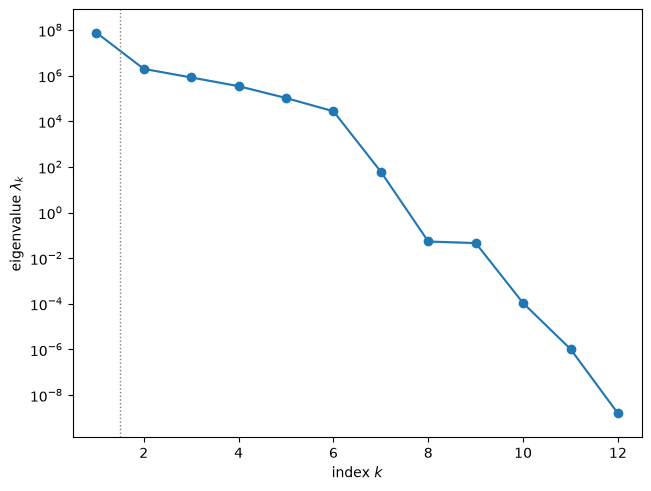

In [5]:
fig, ax = ac.plotting.plot_eigenvalues(sub)
plt.close(fig)
fig

$\lambda_1 = 7.694\times10^7$ (95 % bootstrap range $7.401$–$8.058\times10^7$) is 38.8 times $\lambda_2 = 1.985\times10^6$ and holds 95.89 % of the trace. The next ratios are small ($\lambda_2/\lambda_3 = 2.37$, $\lambda_3/\lambda_4 = 2.41$), and the eigenvalue-gap rule picks $n = 1$. (The eigenvalues are in (m³)², the square of $y$'s units, per unit normalized input.) After $\lambda_6$ the spectrum falls by more than two orders of magnitude, and $\lambda_7$ to $\lambda_{12}$ together hold $7.7\times10^{-7}$ of the trace. Six inputs ($I_a$, $k_c$, $M_f$, $E_a$, $E_c$, $A$) carry practically all the variation, and the other six span a nearly null subspace.

bootstrap mean subspace distance, k = 1..6: [0.005 0.025 0.031 0.025 0.02  0.001]


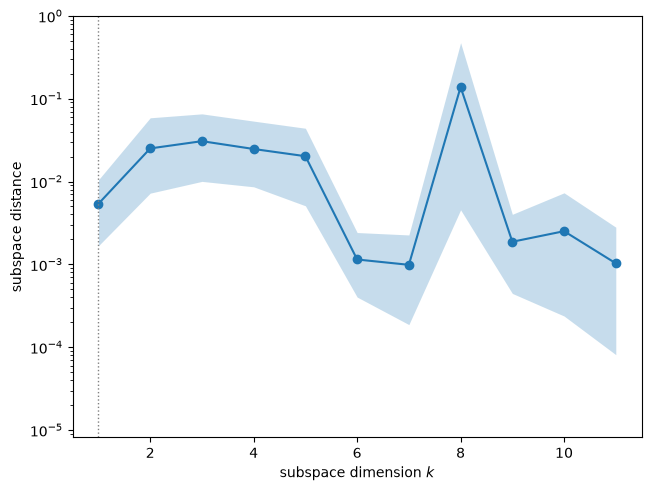

In [6]:
fig, ax = ac.plotting.plot_subspace_errors(sub)
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..6:',
      np.array2string(sub.bootstrap_distances.mean(axis=0)[:6], precision=3))
fig

The bootstrap mean subspace distance is 0.005 for $n = 1$, so with 2000 exact gradients and a gap of 38.8, $\mathbf w_1$ is well determined. For $k = 2$ to 5 the distances are larger (0.02 to 0.031), because successive eigenvalues from $\lambda_2$ to $\lambda_6$ differ by factors of only 2.4 to 3.8. For $k = 6$ it falls to 0.001: the six-dimensional subspace of the six influential inputs is separated from the rest by the large gap $\lambda_6/\lambda_7$.

w1: Delta -0.000, gamma +0.000, A +0.173, T_a -0.000, w +0.001, v +0.001, k_c +0.491, I_a +0.602, E_a -0.361, E_c -0.243, M_f -0.422, P -0.015
w2: Delta +0.000, gamma -0.000, A -0.073, T_a +0.000, w -0.000, v -0.000, k_c -0.546, I_a +0.775, E_a +0.163, E_c +0.106, M_f +0.239, P +0.017
normalized gradient of log y at the midpoint, unit length: Delta -0.000, gamma +0.000, A +0.175, T_a -0.000, w +0.001, v +0.001, k_c +0.514, I_a +0.633, E_a -0.332, E_c -0.234, M_f -0.373, P -0.016
|w1 . (that direction)| = 0.9976
half-range / midpoint (%): Delta 0.5, gamma 0.8, A 15.0, T_a 1.0, w 5.0, v 5.5, k_c 43.4, I_a 54.2, E_a 28.5, E_c 20.0, M_f 32.0, P 100.0


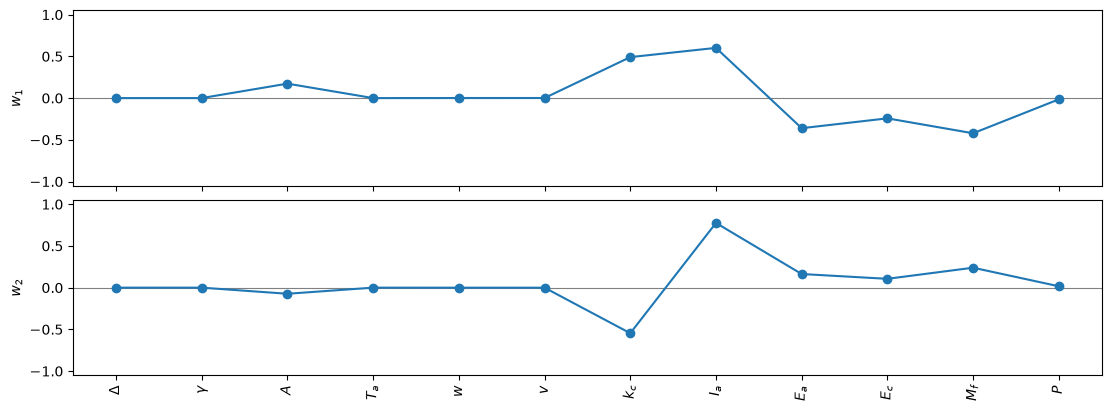

In [7]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, figsize=(11, 4))
plt.close(fig)
w1, w2 = W[:, 0], W[:, 1]
print('w1:', ', '.join(f'{n} {v:+.3f}' for n, v in zip(names, w1)))
print('w2:', ', '.join(f'{n} {v:+.3f}' for n, v in zip(names, w2)))
# For a product of powers, the normalized gradient of log y is constant: d log y / d xi_j = p_j h_j / x_j at the midpoint
hr = (im.UPPER - im.LOWER) / 2
d0 = im.grad_iww(x0)[0] * hr / im.iww(x0)[0]
print('normalized gradient of log y at the midpoint, unit length:',
      ', '.join(f'{n} {v:+.3f}' for n, v in zip(names, d0 / np.linalg.norm(d0))))
print(f'|w1 . (that direction)| = {abs(w1 @ d0) / np.linalg.norm(d0):.4f}')
print('half-range / midpoint (%):', ', '.join(f'{n} {100 * h_ / m_:.1f}' for n, h_, m_ in zip(names, hr, x0)))
fig

$\mathbf w_1$ weights $I_a$ by $+0.602$, $k_c$ by $+0.491$, $M_f$ by $-0.422$, $E_a$ by $-0.361$, $E_c$ by $-0.243$ and $A$ by $+0.173$. $P$ has weight $-0.015$, and the five other weather inputs have weights of $10^{-3}$ or less. The signs are physical: the withdrawal grows with the irrigated area, the crop's water need and the radiation, and falls as any of the three efficiencies rises. The reason for the direction is the model's form. Apart from the small terms in $P$ and in the weather inputs other than $A$, $y$ is proportional to $I_a\,k_c\,A/(E_a E_c M_f)$, a product of powers $\pm1$. For such a product, the gradient of $\log y$ with respect to the normalized inputs is $\pm h_j/x_j$, with $h_j$ the half-range of input $j$, i.e. the input's relative half-range. At the midpoint, this direction is the third printed line, and $|\mathbf w_1\cdot$ it$| = 0.9976$. So $\mathbf w_1$ ranks the inputs mainly by how wide Table S4 makes them relative to their size (last printed line): $I_a$ (half-range 54.2 % of its midpoint) and $k_c$ (43.4 %) lead, then $M_f$ (32.0 %), $E_a$ (28.5 %), $E_c$ (20.0 %) and $A$ (15.0 %). $\mathbf w_2$ mostly contrasts $I_a$ ($+0.775$) with $k_c$ ($-0.546$).

active variable y1 = w1^T x: range [-1.74, 1.59]; corr(y, y1) = 0.9491; corr(log y, y1) = 0.9883


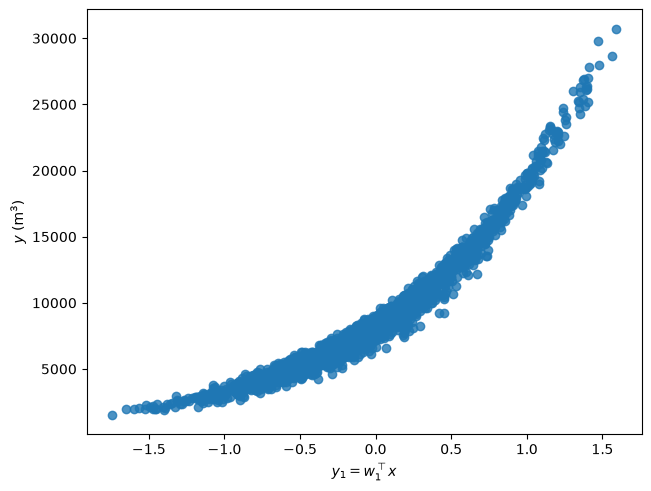

In [8]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=1, qoi_label=r'$y$ (m$^3$)')
plt.close(fig)
y_act = space.to_normalized(X) @ W[:, :2]
print(f'active variable y1 = w1^T x: range [{y_act[:, 0].min():.2f}, {y_act[:, 0].max():.2f}]; '
      f'corr(y, y1) = {np.corrcoef(f, y_act[:, 0])[0, 1]:.4f}; corr(log y, y1) = {np.corrcoef(np.log(f), y_act[:, 0])[0, 1]:.4f}')
fig

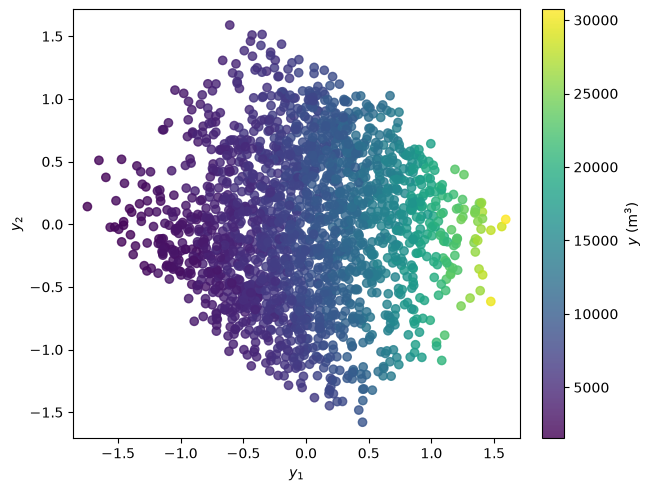

In [9]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=2, qoi_label=r'$y$ (m$^3$)')
plt.close(fig)
fig

Against $y_1 = \mathbf w_1^T\mathbf x$ (range $-1.74$ to $1.59$), $y$ lies on a narrow, convex band that widens as $y$ grows. The correlation of $y$ with $y_1$ is 0.9491, and that of $\log y$ with $y_1$ is 0.9883, as expected for a near-product: $\log y$ is close to linear in $y_1$, so $y$ is close to exponential in it. In the $(y_1, y_2)$ plot the colour changes mostly along $y_1$.

#### Surrogates on the active variables

We fit polynomials in the active variables and report the leave-one-out $R^2$ (`loo_r_squared`). The figure shows the cubic in $y_1$.

LOO R^2: n = 1, degree 1: 0.9003; n = 1, degree 2: 0.9816; n = 1, degree 3: 0.9848; n = 2, degree 2: 0.9882; n = 2, degree 3: 0.9924; n = 3, degree 3: 0.9976


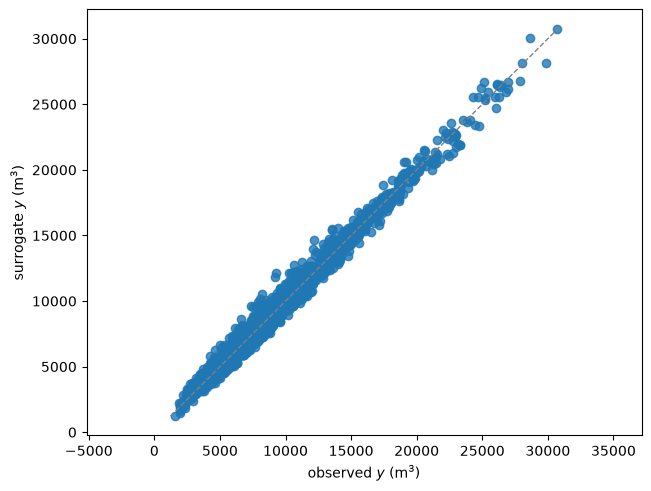

In [10]:
fits = {}
for n_, deg in [(1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3)]:
    fits[n_, deg] = ac.fit_surrogate(X=X, f=f, subspace=ac.with_dimension(sub, n_), kind='poly', degree=deg)
print('LOO R^2: ' + '; '.join(f'n = {n_}, degree {d}: {s.loo_r_squared:.4f}' for (n_, d), s in fits.items()))
fig, ax = ac.plotting.plot_surrogate_fit(fits[1, 3], X=X, f=f, qoi_label=r'$y$ (m$^3$)')
plt.close(fig)
fig

In $y_1$ alone, a line has leave-one-out $R^2 = 0.9003$, a quadratic 0.9816 and a cubic 0.9848. A second active variable raises the cubic's $R^2$ to 0.9924, and a third to 0.9976. We use $n = 1$. The gap $\lambda_1/\lambda_2 = 38.8$ is the only large one before $\lambda_6$, $\mathbf w_1$ is well determined (bootstrap distance 0.005), and a cubic in one variable already explains 98.5 % of the variance of $y$ in cross-validation. The remaining 1.5 % comes from the spread around the band: at a fixed $y_1$, different mixes of area, crop coefficient and efficiencies give somewhat different products.

### Comparison with the paper

The paper reports, for this cell and day, the point estimate at the mean of every input (8600 m³; Comment p. 2, supplement p. 19), the spread of $y$ (Comment p. 2: "between 1400 and 40,000 m³"; supplement p. 19: 3000–21,000 m³ between the 2.5th and 97.5th percentiles, "with the right tail pushing estimates up to 40,000 m³"), the statement that interactions among $E_a$, $E_c$, $I_a$, $k_c$ and $M_f$ explain "c. 10%" of the variance (p. 19), and first-order, total-order and selected second-order Sobol' indices in Fig. S13b–c (p. 21), as bar and dot plots without printed values.

**Sobol' indices.** We use the estimators the supplement states (section 2.2, pp. 14–15): the Saltelli et al. first-order estimator (Eq. 14) [[6]](https://doi.org/10.1016/j.cpc.2009.09.018) and the Jansen total-order estimator (Eq. 15) [[7]](https://doi.org/10.1016/S0010-4655(98)00154-4), on base matrices $\mathbf A$ and $\mathbf B$ of $N = 2^{15}$ rows (the $N$ of the archived code) from one scrambled Sobol' sequence. For the nine pairs of Fig. S13c, we estimate second-order indices from the closed index of each pair with the matrix $\mathbf A_{\mathbf B}^{(ij)}$ (columns $i$ and $j$ from $\mathbf B$), an estimator of this data set's choosing (`sobol_tools.py`; `check_accuracy.py` checks it on a test function with known indices). The 95 % intervals are the estimate $\pm 1.96$ bootstrap standard deviations over 1000 resamples of the rows (the error bars of the supplement's Fig. S13c are 95 % intervals by "the normal method" over 10³ bootstrap samples, p. 21).

In [11]:
pairs_named = [('k_c', 'E_c'), ('I_a', 'A'), ('E_a', 'M_f'), ('I_a', 'E_c'), ('k_c', 'E_a'),
               ('k_c', 'M_f'), ('I_a', 'E_a'), ('I_a', 'M_f'), ('I_a', 'k_c')]      # Fig. S13c, in its order
pairs = [(names.index(a), names.index(b)) for a, b in pairs_named]
N_SOBOL = 2 ** 15
A_mat, B_mat = st.base_matrices(N_SOBOL, im.M, seed=SEED)
to_physical = lambda Uq: im.LOWER + (im.UPPER - im.LOWER) * Uq
ys = st.evaluate(lambda Uq: im.iww(to_physical(Uq)), A_mat, B_mat, pairs)
(S, T, S2), (sdS, sdT, sdS2) = st.bootstrap(ys, pairs, R=1000, seed=SEED)
print(f'{N_SOBOL * (im.M + 2 + len(pairs))} model runs; V(y) = {np.var(np.r_[ys["A"], ys["B"]]):.4g} (m^3)^2')
print(f"{'input':6s} {'S_i':>8s} {'95% CI':>17s} {'T_i':>8s} {'95% CI':>17s}")
for j in np.argsort(-T):
    print(f'{names[j]:6s} {S[j]:8.4f} [{S[j] - 1.96 * sdS[j]:7.4f}, {S[j] + 1.96 * sdS[j]:7.4f}] '
          f'{T[j]:8.4f} [{T[j] - 1.96 * sdT[j]:7.4f}, {T[j] + 1.96 * sdT[j]:7.4f}]')
print(f'sum of S_i = {S.sum():.4f}; 1 - sum S_i = {1 - S.sum():.4f}; sum of the nine S_ij = {S2.sum():.4f}')
print('S_ij: ' + ', '.join(f'{a}.{b} {s:.4f} [{s - 1.96 * e:.4f}, {s + 1.96 * e:.4f}]'
                           for (a, b), s, e in zip(pairs_named, S2, sdS2)))
print(f'largest 95% half-widths (1.96 bootstrap sd): S_i {1.96 * sdS.max():.4f}, T_i {1.96 * sdT.max():.4f}, '
      f'S_ij {1.96 * sdS2.max():.4f}')

753664 model runs; V(y) = 2.327e+07 (m^3)^2
input       S_i            95% CI      T_i            95% CI
I_a      0.3587 [ 0.3369,  0.3806]   0.4150 [ 0.4064,  0.4235]
k_c      0.2348 [ 0.2170,  0.2525]   0.2817 [ 0.2758,  0.2877]
M_f      0.1352 [ 0.1214,  0.1490]   0.1664 [ 0.1628,  0.1700]
E_a      0.1055 [ 0.0933,  0.1177]   0.1308 [ 0.1279,  0.1336]
E_c      0.0503 [ 0.0420,  0.0587]   0.0632 [ 0.0618,  0.0646]
A        0.0264 [ 0.0201,  0.0328]   0.0344 [ 0.0336,  0.0352]
P        0.0003 [-0.0003,  0.0008]   0.0003 [ 0.0003,  0.0003]
v       -0.0000 [-0.0000,  0.0000]   0.0000 [ 0.0000,  0.0000]
w        0.0000 [-0.0000,  0.0000]   0.0000 [ 0.0000,  0.0000]
gamma   -0.0000 [-0.0000,  0.0000]   0.0000 [ 0.0000,  0.0000]
Delta    0.0000 [-0.0000,  0.0000]   0.0000 [ 0.0000,  0.0000]
T_a     -0.0000 [-0.0000,  0.0000]   0.0000 [ 0.0000,  0.0000]
sum of S_i = 0.9112; 1 - sum S_i = 0.0888; sum of the nine S_ij = 0.0790
S_ij: k_c.E_c 0.0032 [0.0001, 0.0062], I_a.A 0.0037 [0.0012, 0.006

The supplement prints no index values, so we compare with approximate read-offs from its Fig. S13b–c (p. 21), labelled as such in the table below. The same six inputs matter, in the same order: $I_a$ ($S_i = 0.3587$, $T_i = 0.4150$), $k_c$ (0.2348, 0.2817), $M_f$ (0.1352, 0.1664), $E_a$ (0.1055, 0.1308), $E_c$ (0.0503, 0.0632) and $A$ (0.0264, 0.0344). Every other total index is below $10^{-3}$. All twelve indices lie within about 0.01 of the read-offs. The first-order indices sum to 0.9112, so interactions explain $1 - \sum S_i = 0.0888$ of the variance, matching the paper's "c. 10%" (p. 19). The nine second-order indices of Fig. S13c come out in the paper's order, from $k_c E_c$ (0.0032) to $I_a k_c$ (0.0242), and sum to 0.0790. The 95 % intervals have half-widths of at most 0.0219 ($S_i$), 0.0086 ($T_i$) and 0.0075 ($S_{ij}$).

**Activity scores and total-order indices.** The diagonal of $\mathbf C$, $C_{jj} = \sum_k \lambda_k w_{jk}^2$, is the activity score of input $j$ over all twelve eigenpairs [[4]](https://doi.org/10.1016/j.ress.2017.01.013), and for an input uniform on $[-1, 1]$ it bounds the total-order index: $T_j \le 4\,C_{jj}/(\pi^2\,V(y))$ [[5]](https://doi.org/10.1016/j.matcom.2009.01.023). We compare the two rankings and check the bound.

In [12]:
alpha_all = ac.activity_scores(sub, n=im.M)        # = diag(C)
alpha_1 = ac.activity_scores(sub, n=1)
Vy = np.var(np.r_[ys['A'], ys['B']])               # the V(y) of the Sobol' indices
bound = 4 * alpha_all / (np.pi ** 2 * Vy)
print(f"{'input':6s} {'alpha (n=12)':>13s} {'alpha (n=1)':>12s} {'share':>7s} {'T_i':>7s} {'bound':>7s}")
for j in np.argsort(-alpha_all):
    print(f'{names[j]:6s} {alpha_all[j]:13.4g} {alpha_1[j]:12.4g} {alpha_all[j] / alpha_all.sum():7.4f} '
          f'{T[j]:7.4f} {bound[j]:7.4f}')
top = np.argsort(-T)[:6]
print(f'same order of the six leading inputs: {list(np.argsort(-alpha_all)[:6]) == list(top)}; '
      f'bound holds for every input: {np.all(T <= bound)}')

input   alpha (n=12)  alpha (n=1)   share     T_i   bound
I_a        2.907e+07    2.785e+07  0.3623  0.4150  0.5064
k_c        1.951e+07    1.854e+07  0.2431  0.2817  0.3398
M_f        1.424e+07    1.368e+07  0.1775  0.1664  0.2481
E_a        1.038e+07    1.001e+07  0.1293  0.1308  0.1807
E_c         4.67e+06    4.539e+06  0.0582  0.0632  0.0814
A          2.362e+06    2.306e+06  0.0294  0.0344  0.0411
P          1.859e+04    1.755e+04  0.0002  0.0003  0.0003
v              62.29        60.75  0.0000  0.0000  0.0000
w              55.06        53.71  0.0000  0.0000  0.0000
gamma           1.38        1.345  0.0000  0.0000  0.0000
Delta         0.5231       0.5098  0.0000  0.0000  0.0000
T_a         0.002613     0.002546  0.0000  0.0000  0.0000
same order of the six leading inputs: True; bound holds for every input: True


The activity scores (from the 2000 gradient samples) rank the six influential inputs exactly as the total-order indices do (from the Sobol' design). Their shares of the trace (0.3623, 0.2431, 0.1775, 0.1293, 0.0582, 0.0294) are close to the total indices (0.4150, 0.2817, 0.1664, 0.1308, 0.0632, 0.0344). The derivative-based bound holds for every input, within a factor of 1.2–1.5 for the six influential ones. Since $\lambda_1$ dominates, the one-dimensional scores $\lambda_1 w_{j1}^2$ (second column) are close to the full ones. So here the active subspace gives the same sensitivity ranking as the variance-based analysis, from far fewer model runs (2000 gradients against 753664 runs), and it also says how the inputs combine: along one direction, close to the gradient of $\log y$.

**Output distribution.** As in the archived code, the distribution of $y$ is taken over the $N$ rows of $\mathbf A$ (here a scrambled Sobol' sequence rather than random numbers), and the point estimate is $y$ at the mean of every input.

N = 32768: min 1234, 2.5% 2825, median 8240, mean 9216, 97.5% 21073, max 40952 m^3
point estimate at the mean of the inputs: 8530.7 m^3; 97.5%/2.5% = 7.46; max/min = 33.2 (1.52 orders of magnitude)
paper vs notebook: point estimate 8600 vs 8531 (-0.8 %); 2.5% 3000 vs 2825; 97.5% 21000 vs 21073; range 1400 to 40000 vs 1234 to 40952


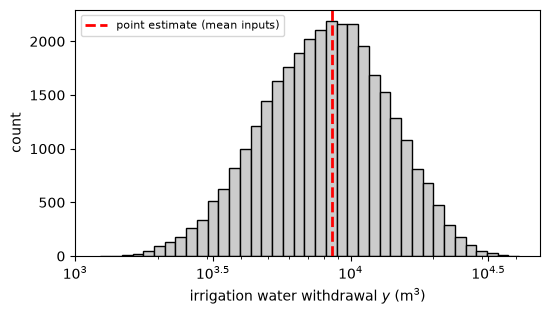

In [13]:
yA = ys['A']
p = np.percentile(yA, [2.5, 50, 97.5])
y0 = im.iww(x0)[0]
print(f'N = {len(yA)}: min {yA.min():.0f}, 2.5% {p[0]:.0f}, median {p[1]:.0f}, mean {yA.mean():.0f}, '
      f'97.5% {p[2]:.0f}, max {yA.max():.0f} m^3')
print(f'point estimate at the mean of the inputs: {y0:.1f} m^3; 97.5%/2.5% = {p[2] / p[0]:.2f}; '
      f'max/min = {yA.max() / yA.min():.1f} ({np.log10(yA.max() / yA.min()):.2f} orders of magnitude)')
print(f'paper vs notebook: point estimate 8600 vs {y0:.0f} ({100 * (y0 - 8600) / 8600:+.1f} %); '
      f'2.5% 3000 vs {p[0]:.0f}; 97.5% 21000 vs {p[2]:.0f}; range 1400 to 40000 vs {yA.min():.0f} to {yA.max():.0f}')
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(yA, bins=np.logspace(np.log10(yA.min()), np.log10(yA.max()), 40), color='0.8', edgecolor='k')
ax.axvline(y0, color='r', ls='--', lw=2, label='point estimate (mean inputs)')
ax.set_xscale('log')
ax.set_xticks(10 ** np.array([3.0, 3.5, 4.0, 4.5]), [r'$10^{3}$', r'$10^{3.5}$', r'$10^{4}$', r'$10^{4.5}$'])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel(r'irrigation water withdrawal $y$ (m$^3$)')
ax.set_ylabel('count')
ax.legend(loc='upper left', fontsize=8)
plt.close(fig)
fig

Over the $N = 32768$ rows of $\mathbf A$, $y$ runs from 1234 to 40952 m³, with 2.5th and 97.5th percentiles 2825 and 21073 m³ and median 8240 m³. The 97.5th percentile is 7.46 times the 2.5th, and the extremes span 1.52 orders of magnitude, the paper's "about one and a half orders of magnitude" (p. 19). The point estimate at the mean inputs, 8530.7 m³, lies a little above the median because $y$ is right-skewed.

| Quantity | Paper value | Notebook value |
|---|---|---|
| Point estimate, mean of every input | 8600 m³ (Comment p. 2; supplement p. 19) | 8531 m³ at the Table S4 midpoint (archived form; −0.8 %); 8635.9 m³ (+0.4 %) at the midpoint of the bounds as the archived code computes them (`check_accuracy.py`, check 4). Eq. 16 as printed: 102852 m³; printed with the division by 31: 3205 m³ |
| 2.5th–97.5th percentile of $y$ | 3000–21,000 m³ (supplement p. 19) | 2825–21073 m³ ($N = 2^{15}$) |
| Range of $y$ | 1400–40,000 m³ (Comment p. 2); right tail "up to 40,000 m³" (supplement p. 19) | 1234–40952 m³ ($N = 2^{15}$; extremes depend on the sample) |
| Interactions, $1 - \sum S_i$ | "c. 10%" (supplement p. 19) | 0.0888 |
| $S_i$ / $T_i$, $I_a$ | ≈ 0.35 / 0.41 (read off Fig. S13b, p. 21) | 0.3587 / 0.4150 |
| $S_i$ / $T_i$, $k_c$ | ≈ 0.225 / 0.27 (read-off) | 0.2348 / 0.2817 |
| $S_i$ / $T_i$, $M_f$ | ≈ 0.145 / 0.17 (read-off) | 0.1352 / 0.1664 |
| $S_i$ / $T_i$, $E_a$ | ≈ 0.11 / 0.13 (read-off) | 0.1055 / 0.1308 |
| $S_i$ / $T_i$, $E_c$ | ≈ 0.05 / 0.06 (read-off) | 0.0503 / 0.0632 |
| $S_i$ / $T_i$, $A$ | ≈ 0.03 / 0.035 (read-off) | 0.0264 / 0.0344 |
| $S_i$, $T_i$ of $\Delta$, $\gamma$, $T_a$, $w$, $v$, $P$ | ≈ 0 (read-off) | all below $10^{-3}$ |
| $S_{ij}$, $I_a k_c$ / $I_a M_f$ / $I_a E_a$ | ≈ 0.025 / 0.017 / 0.0095 (read off Fig. S13c, p. 21) | 0.0242 / 0.0135 / 0.0102 |
| $S_{ij}$, $k_c M_f$ / $k_c E_a$ / $I_a E_c$ | ≈ 0.008 / 0.006 / 0.0055 (read-off) | 0.0089 / 0.0069 / 0.0048 |
| $S_{ij}$, $E_a M_f$ / $I_a A$ / $k_c E_c$ | ≈ 0.004 / 0.003 / 0.003 (read-off) | 0.0037 / 0.0037 / 0.0032 |
| Active subspace | not studied | $n = 1$, $\lambda_1/\lambda_2 = 38.8$, 95.89 % of the trace |

The Sobol' indices and the percentiles agree with the paper within the precision of the read-offs and of the paper's rounded values. Our 2.5th percentile, 2825 m³, is below the paper's 3000, which is printed to one significant figure. The extremes of a Monte Carlo sample depend on the sample. Ours is a scrambled Sobol' sequence. Section 2.2 (p. 14) says Sobol' quasi-random numbers were used, but the archived code passes `type = "R"` to the sensobol package's `sobol_matrices`. The sensobol documentation (CRAN reference manual, version 1.2.0, p. 23) says `type = "R"` "uses random numbers" and the default `"QRN"` uses Sobol' quasi-random numbers, so the code disagrees with section 2.2.

**The point estimate.** At the Table S4 midpoint, $y$ is 0.8 % below the paper's 8600 m³. The gap comes from the input bounds. The archived code does not use Table S4's printed values. It computes the bounds of $\Delta$, $\gamma$, $T_a$ and $v$ from the archived climate data for January 6–7, takes $k_c$, $E_a$ and $E_c$ from the archived data files, and uses $350 \pm 15\,\%$ for $A$ and $2.81 \pm 5\,\%$ for $w$. At the midpoint of those bounds (rebuilt in `check_accuracy.py`, check 4, from the archived values), $y = 8635.9$ m³, 0.4 % above 8600 m³. The rest is within the rounding of "8600", and the paper evaluates $y$ at the sample means of its inputs rather than at the exact midpoints. Table S4 differs most from the code's bounds in $T_a$ (midpoint 10 °C against 11 °C) and $v$ (0.275 against 0.41154 kPa). Between the two midpoints, $y$ rises from 8530.7 to 8635.9 m³. Taking only the code's $k_c$ bounds (0.45643–1.14422, which Table S4 truncates to 0.45–1.14) raises $y$ by 0.68 %, and taking only its weather bounds ($\Delta$, $\gamma$, $T_a$, $w$, $v$) raises it by 0.55 % (check 4). These are shifts of the midpoint; the weather inputs' Sobol' indices stay near zero. We keep Table S4 as this data set's input space, since it is the distribution the paper states.

### References

[1] A. Puy, R. Sheikholeslami, H. V. Gupta, J. W. Hall, B. Lankford, S. Lo Piano, J. Meier, F. Pappenberger, A. Porporato, G. Vico, and A. Saltelli. [The delusive accuracy of global irrigation water withdrawal estimates](https://doi.org/10.1038/s41467-022-30731-8). *Nature Communications* 13:3183, 2022.

[2] A. Puy et al. [Supplementary Materials for The delusive accuracy of global irrigation water withdrawal estimates](https://doi.org/10.5281/zenodo.5528844). Zenodo, version 1.0.4, 2021 (`supplementary_materials.pdf` and the code `code_ghm_auditing.R`; also at https://github.com/arnaldpuy/ghm_auditing). Source of the model (Eq. 16, section 2.5), the input ranges (Table S4) and the archived code whose form of Eq. 16 is used here.

[3] P. G. Constantine, E. Dow, and Q. Wang. [Active subspace methods in theory and practice: applications to kriging surfaces](https://doi.org/10.1137/130916138). *SIAM Journal on Scientific Computing* 36(4):A1500–A1524, 2014.

[4] P. G. Constantine and P. Diaz. [Global sensitivity metrics from active subspaces](https://doi.org/10.1016/j.ress.2017.01.013). *Reliability Engineering & System Safety* 162:1–13, 2017.

[5] I. M. Sobol' and S. Kucherenko. [Derivative based global sensitivity measures and their link with global sensitivity indices](https://doi.org/10.1016/j.matcom.2009.01.023). *Mathematics and Computers in Simulation* 79(10):3009–3017, 2009.

[6] A. Saltelli, P. Annoni, I. Azzini, F. Campolongo, M. Ratto, and S. Tarantola. [Variance based sensitivity analysis of model output. Design and estimator for the total sensitivity index](https://doi.org/10.1016/j.cpc.2009.09.018). *Computer Physics Communications* 181(2):259–270, 2010.

[7] M. J. W. Jansen. [Analysis of variance designs for model output](https://doi.org/10.1016/S0010-4655(98)00154-4). *Computer Physics Communications* 117(1–2):35–43, 1999.

In [14]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 18.6 s
